# Intelligent Agents: Reflex-Based Agents for the Vacuum-cleaner World

Student Name: Đào Duy Hưng

I have used the following AI tools: no

I understand that my submission needs to be my own work: DDH

## Learning Outcomes

* Design and build a simulation environment that models sensor inputs, actuator effects, and performance measurement.
* Apply core AI concepts by implementing the agent function for a simple and model-based reflex agents that respond to environmental percepts.
* Practice how the environment and the agent function interact.
* Analyze agent performance through controlled experiments across different environment configurations.
* Graduate Students: Develop strategies for handling uncertainty and imperfect information in autonomous agent systems.

## Instructions

Total Points: 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file.

### AI Use

Here are some guidelines that will make it easier for you:

* __Don't:__ Rely on AI auto completion. You will waste a lot of time trying to figure out how the suggested code relates to what we do in class. Turn off AI code completion (e.g., Copilot) in your IDE.
* __Don't:__ Do not submit code/text that you do not understand or have not checked to make sure that it is complete and correct.
* __Do:__ Use AI for debugging and letting it explain code and concepts from class.

### Using Visual Studio Code

Follow [HOWTO Setup the Used Tools] to set up your Jupyter Notebook environment.
You can use `Export` (click on `...` in the menu bar) in VS Code to save your notebook as a HTML file. Don't forget to run all blocks before, so the HTML file contains the output of the executed code.

### Using Google Colab

In Colab you need to save the notebook on GoogleDrive to work with it. For this you need to mount your google dive and change to the correct directory. The following code will try to do this if you are on Colab.

In [4]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

Mounted at /content/drive
Your working directory is now Google Drive: My Drive > Colab Notebooks


Once you are done with the assignment and have run all code blocks using `Runtime/Run all`, you can convert your notebook on GoogleDrive into HTML
using: [Convert a Jupyter Notebook to HTML using Colab](https://colab.research.google.com/github/mhahsler/Introduction_to_Artificial_Intelligence/blob/master/HOWTOs/colab_to_html.ipynb).

## Introduction

In this assignment you will implement a simulator environment for an automatic vacuum cleaner robot, a set of different reflex-based agent programs, and perform a comparison study for cleaning a single room. Focus on the __cleaning phase__ which starts when the robot is activated and ends when the last dirty square in the room has been cleaned. Someone else will take care of the agent program needed to navigate back to the charging station after the room is clean.

## PEAS description of the cleaning phase

The PEAS description is used in the design phase for an intelligent agent. Make sure your implementations follow this description:

* __Performance Measure:__ Each action costs 1 energy unit. The performance is measured as the sum of the energy units used to clean the whole room.

* __Environment:__ A room with $n \times n$ squares where $n = 5$. Dirt is randomly placed on each square with probability $p = 0.2$. For simplicity, you can assume that the agent knows the size and the layout of the room (i.e., it knows $n$). To start, the agent is placed on a random square.

* __Actuators:__ The agent can clean the current square (action `suck`) or move to an adjacent square by going `north`, `east`, `south`, or `west`.

* __Sensors:__ Four bumper sensors, one for north, east, south, and west; a dirt sensor reporting dirt in the current square.  


## The agent program for a simple randomized agent

To show the structure of an agent program, I implement here a simple randomized agent that chooses its actions randomly.

The agent program is implemented as a function that gets sensor information (the current percepts) as the arguments.
We will use the parameters:

* `bumpers`: A dictionary with boolean entries for the for bumper sensors `north`, `east`, `west`, `south`. E.g., if the agent is on the north-west corner, `bumpers` will be `{"north" : True, "east" : False, "south" : False, "west" : True}`.
* `dirty`: A boolean representing the dirt sensor.

The agent returns the chosen action as a string.

Here is an example implementation for the agent program of a simple randomized agent:  

In [5]:
# Google Colab or if you are missing a package: Uncomment the %pip command below, run this block, and restart the session.
# %pip install -q "numpy>=1.26,<3"

In [6]:
import numpy as np

actions = ["north", "east", "west", "south", "suck"]

def simple_randomized_agent(bumpers, dirty):
    return np.random.choice(actions)

In [7]:
# define percepts (current location is NW corner and it is dirty)
bumpers = {"north" : True, "east" : False, "south" : False, "west" : True}
dirty = True

# call agent program function with percepts and it returns an action
simple_randomized_agent(bumpers, dirty)

np.str_('suck')

__Note:__ This is not a rational intelligent agent. It ignores its sensors and may bump into a wall repeatedly or not clean a dirty square. You will be asked to implement rational agents below.

## Simple environment example

I show here how to implement a simple simulation environment that supplies the agent program with its percepts and evaluates the agent's actions.
As an example, I implement a room of infinite in size (bumpers are always `False`) where every square is always dirty, even if the agent cleans it. The environment function returns a different performance measure than the one specified in the PEAS description! Since the room is infinite and all squares are constantly dirty, the agent can never clean the whole room. Your implementation needs to implement the **correct performance measure.** The energy budget of the agent is specified as `max_steps`.

In [8]:
def simple_environment(agent_function, max_steps, verbose = True):
    num_cleaned = 0

    for i in range(max_steps):
        dirty = True
        bumpers = {"north" : False, "south" : False, "west" : False, "east" : False}

        action = agent_function(bumpers, dirty)
        if (verbose): print("step", i , "- action:", action)

        if (action == "suck"):
            num_cleaned = num_cleaned + 1

    return num_cleaned



Do one simulation run with a simple randomized agent that has enough energy for 20 steps.

In [9]:
simple_environment(simple_randomized_agent, max_steps = 20)

step 0 - action: suck
step 1 - action: east
step 2 - action: suck
step 3 - action: east
step 4 - action: north
step 5 - action: suck
step 6 - action: west
step 7 - action: suck
step 8 - action: south
step 9 - action: north
step 10 - action: east
step 11 - action: suck
step 12 - action: suck
step 13 - action: suck
step 14 - action: west
step 15 - action: west
step 16 - action: south
step 17 - action: east
step 18 - action: suck
step 19 - action: south


8

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally.
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.


## Task 1: Implement a simulation environment [20 Points]

The simple environment above is not very realistic. Your environment simulator needs to follow the PEAS description from above. It needs to:

* Initialize the environment by storing the state of each square (clean/dirty) and making some dirty. ([Help with random numbers and arrays in Python])
* Keep track of the agent's position.
* Call the agent function repeatedly and provide the agent function with the sensor inputs.  
* React to the agent's actions. E.g, by removing dirt from a square or moving the agent around unless there is a wall in the way.
* Keep track of the performance measure. That is, track the agent's actions until all dirty squares are clean and count the number of actions it takes the agent to complete the task.

The easiest implementation for the environment is to hold an 2-dimensional array to represent if squares are clean or dirty and to call the agent function in a loop until all squares are clean or a predefined number of steps have been reached (i.e., the robot runs out of energy).

The simulation environment should be a function like the `simple_environment()` and needs to work with the simple randomized agent program from above. **Use the same environment for all your agent implementations in the tasks below.**

*Note on debugging:* Debugging can be difficult. Here are a few options:

* Make sure your environment prints enough information when you use `verbose = True`.
* VSCode also provides a very good interactive Python debugger for notebooks. Read the [HOWTO on debugging](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/debugging_in_notebooks.ipynb) for more details.
* Another very useful debugging help is to implement a function that the environment can use to displays the room with dirt and the current position of the robot at every step. You can use simple characters for dirt and the robot location.  

In [10]:
# Your code and description goes here
import numpy as np

# Các hành động hợp lệ của robot
actions = ["north", "east", "west", "south", "suck"]


def vacuum_environment(
    agent_function,
    n=5,
    dirt_probability=0.2,
    max_steps=10000,
    verbose=False,
    initial_room=None,
    start_position=None,
    seed=None,
    return_details=False
):
    """
    Mô phỏng môi trường Robot Vacuum n x n.

    Parameters
    ----------
    agent_function : function
        Agent có dạng agent_function(bumpers, dirty).

    n : int
        Kích thước phòng n x n.

    dirt_probability : float
        Xác suất một ô ban đầu có bụi.

    max_steps : int
        Giới hạn số action robot được phép thực hiện.

    verbose : bool
        Nếu True, in thông tin từng bước.

    initial_room : numpy.ndarray or None
        Cho phép truyền trước một room để so sánh công bằng giữa các agent.

    start_position : tuple or None
        Vị trí bắt đầu của robot.

    seed : int or None
        Seed để tái lập kết quả.

    return_details : bool
        Nếu True trả về dictionary chứa thông tin chi tiết.
        Nếu False chỉ trả về số bước.
    """

    rng = np.random.default_rng(seed)

    # ---------------------------------------------------------
    # 1. Khởi tạo phòng
    # True  = dirty
    # False = clean
    # ---------------------------------------------------------
    if initial_room is None:
        room = rng.random((n, n)) < dirt_probability
    else:
        room = np.array(initial_room, dtype=bool, copy=True)

        if room.shape != (n, n):
            raise ValueError(
                f"initial_room phải có kích thước {(n, n)}"
            )

    # ---------------------------------------------------------
    # 2. Khởi tạo vị trí robot
    # ---------------------------------------------------------
    if start_position is None:
        position = [
            int(rng.integers(0, n)),
            int(rng.integers(0, n))
        ]
    else:
        position = [
            int(start_position[0]),
            int(start_position[1])
        ]

    # Đếm số ô bẩn ban đầu
    remaining_dirt = int(room.sum())
    initial_dirt = remaining_dirt

    # Performance Measure:
    # mỗi action tốn 1 energy unit
    steps = 0

    # ---------------------------------------------------------
    # 3. Vòng lặp simulation
    # ---------------------------------------------------------
    while remaining_dirt > 0 and steps < max_steps:

        row, col = position

        # -----------------------------------------------------
        # Sensors: 4 bumper sensors
        # -----------------------------------------------------
        bumpers = {
            "north": row == 0,
            "east": col == n - 1,
            "south": row == n - 1,
            "west": col == 0
        }

        # Dirt sensor
        dirty = bool(room[row, col])

        # -----------------------------------------------------
        # Agent nhận percept và chọn action
        # -----------------------------------------------------
        action = agent_function(bumpers, dirty)

        if action not in actions:
            raise ValueError(
                f"Agent trả về action không hợp lệ: {action}"
            )

        # -----------------------------------------------------
        # 4. Environment thực hiện action
        # -----------------------------------------------------
        if action == "suck":

            # Chỉ giảm số dirt nếu ô thực sự đang bẩn
            if room[row, col]:
                room[row, col] = False
                remaining_dirt -= 1

        elif action == "north" and not bumpers["north"]:
            position[0] -= 1

        elif action == "east" and not bumpers["east"]:
            position[1] += 1

        elif action == "south" and not bumpers["south"]:
            position[0] += 1

        elif action == "west" and not bumpers["west"]:
            position[1] -= 1

        # Dù robot đâm tường hoặc suck ô sạch,
        # action vẫn tiêu tốn 1 energy unit
        steps += 1

        if verbose:
            print(
                f"Step {steps:3d} | "
                f"Action: {action:5s} | "
                f"Position: {tuple(position)} | "
                f"Remaining dirt: {remaining_dirt}"
            )

    # ---------------------------------------------------------
    # 5. Kết quả
    # ---------------------------------------------------------
    result = {
        "steps": steps,
        "cleaned_all": remaining_dirt == 0,
        "initial_dirt": initial_dirt,
        "remaining_dirt": remaining_dirt,
        "final_position": tuple(position)
    }

    if return_details:
        return result

    return steps

Show that your environment works with the simple randomized agent from above.

In [11]:
# Your code and description goes here

result_random = vacuum_environment(
    agent_function=simple_randomized_agent,
    n=5,
    dirt_probability=0.2,
    max_steps=20,
    seed=42,
    verbose=True,
    return_details=True
)

print("\nSimulation result:")
print(result_random)

Step   1 | Action: west  | Position: (3, 0) | Remaining dirt: 3
Step   2 | Action: suck  | Position: (3, 0) | Remaining dirt: 3
Step   3 | Action: suck  | Position: (3, 0) | Remaining dirt: 3
Step   4 | Action: suck  | Position: (3, 0) | Remaining dirt: 3
Step   5 | Action: west  | Position: (3, 0) | Remaining dirt: 3
Step   6 | Action: north | Position: (2, 0) | Remaining dirt: 3
Step   7 | Action: south | Position: (3, 0) | Remaining dirt: 3
Step   8 | Action: east  | Position: (3, 1) | Remaining dirt: 3
Step   9 | Action: suck  | Position: (3, 1) | Remaining dirt: 3
Step  10 | Action: east  | Position: (3, 2) | Remaining dirt: 3
Step  11 | Action: north | Position: (2, 2) | Remaining dirt: 3
Step  12 | Action: west  | Position: (2, 1) | Remaining dirt: 3
Step  13 | Action: south | Position: (3, 1) | Remaining dirt: 3
Step  14 | Action: east  | Position: (3, 2) | Remaining dirt: 3
Step  15 | Action: south | Position: (4, 2) | Remaining dirt: 3
Step  16 | Action: east  | Position: (4,

## Task 2:  Implement a simple reflex agent [10 Points]

The simple reflex agent randomly walks around but reacts to the bumper sensor by not bumping into the wall and to dirt with sucking. Implement the agent program as a function.

_Note:_ Agents cannot directly use variable in the environment. They only gets the percepts as the arguments to the agent function. Use the function signature for the `simple_randomized_agent` function above.

In [12]:
# Your code and description goes here
def simple_reflex_agent(bumpers, dirty):
    """
    Simple Reflex Agent.

    Luật:
    1. Nếu ô hiện tại bẩn -> suck.
    2. Nếu sạch -> chọn ngẫu nhiên một hướng không có tường.
    """

    # Rule 1: ưu tiên hút bụi
    if dirty:
        return "suck"

    # Rule 2: chỉ lấy các hướng không có tường
    valid_moves = [
        direction
        for direction in ["north", "east", "west", "south"]
        if not bumpers[direction]
    ]

    # Chọn ngẫu nhiên một hướng hợp lệ
    if len(valid_moves) > 0:
        return np.random.choice(valid_moves)

    # Trường hợp đặc biệt n = 1
    return "suck"

Show how the agent works with your environment.

In [13]:
# Your code and description goes here
result_reflex = vacuum_environment(
    agent_function=simple_reflex_agent,
    n=5,
    dirt_probability=0.2,
    max_steps=5000,
    seed=42,
    verbose=True,
    return_details=True
)

print("Simple Reflex Agent result:")
print(result_reflex)

Step   1 | Action: north | Position: (2, 0) | Remaining dirt: 3
Step   2 | Action: north | Position: (1, 0) | Remaining dirt: 3
Step   3 | Action: east  | Position: (1, 1) | Remaining dirt: 3
Step   4 | Action: east  | Position: (1, 2) | Remaining dirt: 3
Step   5 | Action: west  | Position: (1, 1) | Remaining dirt: 3
Step   6 | Action: east  | Position: (1, 2) | Remaining dirt: 3
Step   7 | Action: east  | Position: (1, 3) | Remaining dirt: 3
Step   8 | Action: suck  | Position: (1, 3) | Remaining dirt: 2
Step   9 | Action: south | Position: (2, 3) | Remaining dirt: 2
Step  10 | Action: south | Position: (3, 3) | Remaining dirt: 2
Step  11 | Action: east  | Position: (3, 4) | Remaining dirt: 2
Step  12 | Action: north | Position: (2, 4) | Remaining dirt: 2
Step  13 | Action: north | Position: (1, 4) | Remaining dirt: 2
Step  14 | Action: south | Position: (2, 4) | Remaining dirt: 2
Step  15 | Action: north | Position: (1, 4) | Remaining dirt: 2
Step  16 | Action: south | Position: (2,

## Task 3: Implement a model-based reflex agent [20 Points]

Model-based agents use a state to keep track of what they have done and perceived so far. Your agent needs to find out where it is located and then keep track of its current location. You also need a set of rules based on the state and the percepts to make sure that the agent will clean the whole room. For example, the agent can move to a corner to determine its location and then it can navigate through the whole room and clean dirty squares.

Describe how you define the __agent state__ and how your agent works before implementing it. ([Help with implementing state information in Python])

In [14]:
# Your short description of the state and your implementation goes here
def make_model_based_reflex_agent():
    """
    Tạo Model-Based Reflex Agent với internal state.

    Internal state:
    - phase:
        go_north -> tìm tường phía Bắc
        go_west  -> tìm tường phía Tây
        scan     -> quét toàn bộ phòng

    - position:
        vị trí robot sau khi đã xác định được góc NW.

    - sweep_direction:
        east hoặc west.

    - visited:
        tập các ô robot đã đi qua.
    """

    state = {
        "phase": "go_north",
        "position": None,
        "sweep_direction": "east",
        "visited": set()
    }

    def model_based_reflex_agent(bumpers, dirty):

        # -----------------------------------------------------
        # Nếu đã định vị được thì ghi nhớ ô hiện tại
        # -----------------------------------------------------
        if state["position"] is not None:
            state["visited"].add(
                tuple(state["position"])
            )

        # -----------------------------------------------------
        # Rule 1: nếu có bụi -> hút ngay
        # -----------------------------------------------------
        if dirty:
            return "suck"

        # Có thể chuyển phase mà chưa cần tốn một action
        while True:

            # =================================================
            # PHASE 1: đi lên phía Bắc
            # =================================================
            if state["phase"] == "go_north":

                if not bumpers["north"]:
                    return "north"

                # Đã chạm tường phía Bắc
                state["phase"] = "go_west"

            # =================================================
            # PHASE 2: đi về phía Tây
            # =================================================
            elif state["phase"] == "go_west":

                if not bumpers["west"]:
                    return "west"

                # Đã tới góc North-West
                # => biết chính xác tọa độ hiện tại
                state["phase"] = "scan"
                state["position"] = [0, 0]
                state["sweep_direction"] = "east"

                state["visited"].add((0, 0))

            # =================================================
            # PHASE 3: quét zig-zag
            # =================================================
            else:

                direction = state["sweep_direction"]

                # ---------------------------------------------
                # Tiếp tục đi ngang nếu chưa tới tường
                # ---------------------------------------------
                if not bumpers[direction]:

                    if direction == "east":
                        state["position"][1] += 1

                    else:  # west
                        state["position"][1] -= 1

                    return direction

                # ---------------------------------------------
                # Đã tới cuối hàng -> xuống hàng tiếp theo
                # ---------------------------------------------
                if not bumpers["south"]:

                    state["position"][0] += 1

                    # Đảo hướng quét
                    if direction == "east":
                        state["sweep_direction"] = "west"
                    else:
                        state["sweep_direction"] = "east"

                    return "south"

                # ---------------------------------------------
                # Đã tới hàng cuối cùng.
                # Thực tế environment sẽ dừng khi hết bụi.
                # ---------------------------------------------
                return "suck"

    # Cho phép xem state khi debug
    model_based_reflex_agent.state = state

    return model_based_reflex_agent

In [15]:
# Your code goes here
agent = make_model_based_reflex_agent()

Show how the agent works with your environment.

In [16]:
# Your code goes here
model_agent = make_model_based_reflex_agent()

result_model = vacuum_environment(
    agent_function=model_agent,
    n=5,
    dirt_probability=0.2,
    max_steps=5000,
    seed=42,
    verbose=True,
    return_details=True
)

print("Model-Based Reflex Agent result:")
print(result_model)

print("\nInternal state:")
print(model_agent.state)

print("\nNumber of visited squares:")
print(len(model_agent.state["visited"]))

Step   1 | Action: north | Position: (2, 0) | Remaining dirt: 3
Step   2 | Action: north | Position: (1, 0) | Remaining dirt: 3
Step   3 | Action: north | Position: (0, 0) | Remaining dirt: 3
Step   4 | Action: east  | Position: (0, 1) | Remaining dirt: 3
Step   5 | Action: east  | Position: (0, 2) | Remaining dirt: 3
Step   6 | Action: east  | Position: (0, 3) | Remaining dirt: 3
Step   7 | Action: east  | Position: (0, 4) | Remaining dirt: 3
Step   8 | Action: suck  | Position: (0, 4) | Remaining dirt: 2
Step   9 | Action: south | Position: (1, 4) | Remaining dirt: 2
Step  10 | Action: west  | Position: (1, 3) | Remaining dirt: 2
Step  11 | Action: suck  | Position: (1, 3) | Remaining dirt: 1
Step  12 | Action: west  | Position: (1, 2) | Remaining dirt: 1
Step  13 | Action: west  | Position: (1, 1) | Remaining dirt: 1
Step  14 | Action: west  | Position: (1, 0) | Remaining dirt: 1
Step  15 | Action: south | Position: (2, 0) | Remaining dirt: 1
Step  16 | Action: east  | Position: (2,

## Task 4: Simulation study [30 Points]

Compare the performance (the performance measure is defined in the PEAS description above) of the agents using  environments of different size. Do at least $5 \times 5$, $10 \times 10$ and
$100 \times 100$. Use 100 random runs for each. Present the results using tables and graphs. Discuss the differences between the agents.
([Help with charts and tables in Python](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/charts_and_tables.ipynb))

In [17]:
# Your code goes here
import pandas as pd


def simulation_study(
    sizes=(5, 10, 100),
    runs=100,
    dirt_probability=0.2,
    seed=2026
):
    """
    So sánh 3 agents trên nhiều kích thước phòng.

    Mỗi run:
    - cùng initial room
    - cùng start position
    cho cả ba agents.
    """

    master_rng = np.random.default_rng(seed)

    agent_specs = [
        (
            "Randomized Agent",
            lambda: simple_randomized_agent
        ),
        (
            "Simple Reflex Agent",
            lambda: simple_reflex_agent
        ),
        (
            "Model-Based Reflex Agent",
            make_model_based_reflex_agent
        )
    ]

    rows = []

    for n in sizes:

        print(f"Running {n}x{n} environment...")

        scores = {
            name: []
            for name, _ in agent_specs
        }

        # Safety budget.
        # Thường agent sẽ hoàn thành trước giới hạn này rất nhiều.
        max_steps = 1000 * n * n

        for run_idx in range(runs):

            # -------------------------------------------------
            # Tạo cùng một môi trường cho cả ba agents
            # -------------------------------------------------
            room = (
                master_rng.random((n, n))
                < dirt_probability
            )

            start_position = (
                int(master_rng.integers(0, n)),
                int(master_rng.integers(0, n))
            )

            # -------------------------------------------------
            # Chạy từng agent
            # -------------------------------------------------
            for agent_idx, (name, factory) in enumerate(agent_specs):

                # Seed riêng cho quyết định ngẫu nhiên của agent
                np.random.seed(
                    seed
                    + n * 100000
                    + run_idx * 10
                    + agent_idx
                )

                # Model-based cần state mới mỗi lần
                agent = factory()

                result = vacuum_environment(
                    agent_function=agent,
                    n=n,
                    dirt_probability=dirt_probability,
                    max_steps=max_steps,
                    initial_room=room,
                    start_position=start_position,
                    return_details=True
                )

                # Performance measure chỉ có ý nghĩa
                # nếu agent làm sạch toàn bộ phòng.
                if not result["cleaned_all"]:
                    raise RuntimeError(
                        f"{name} không hoàn thành "
                        f"{n}x{n} tại run {run_idx + 1}. "
                        f"Hãy tăng max_steps."
                    )

                scores[name].append(
                    result["steps"]
                )

        # -----------------------------------------------------
        # Tính trung bình 100 runs
        # -----------------------------------------------------
        row = {
            "Size": f"{n}x{n}"
        }

        for name, _ in agent_specs:
            row[name] = np.mean(scores[name])

        rows.append(row)

    results_df = pd.DataFrame(rows)

    return results_df

In [18]:
results_df = simulation_study(
    sizes=(5, 10, 100),
    runs=100,
    dirt_probability=0.2,
    seed=2026
)

results_df

Running 5x5 environment...
Running 10x10 environment...
Running 100x100 environment...


,Size,Randomized Agent,Simple Reflex Agent,Model-Based Reflex Agent
0,5x5,429.10,95.14,28.34
1,10x10,2948.27,903.65,122.28
2,100x100,827598.43,341471.38,12101.48


Fill out the following table with the average performance measure for 100 random runs (you may also create this table with code):

| Size     | Randomized Agent | Simple Reflex Agent | Model-based Reflex Agent |
|----------|------------------|---------------------|--------------------------|
| 5x5     |429.10|95.14|28.34|
| 10x10   |2948.27|903.65|122.28|
| 100x100 |827598.43|341471.38|12101.48|

Add charts to compare the performance of the different agents.

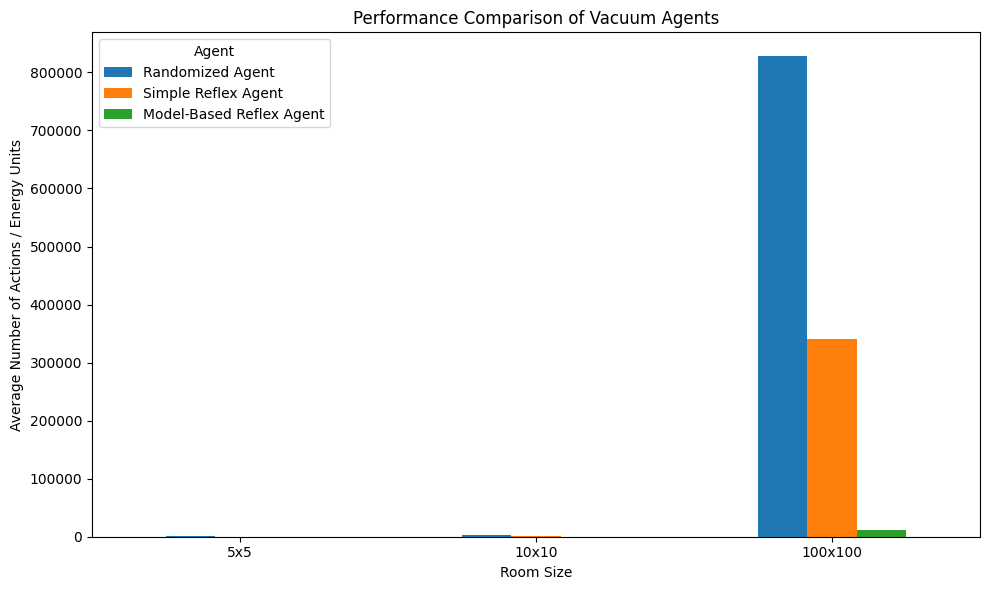

In [19]:
# Your graphs and discussion of the results goes here
import matplotlib.pyplot as plt


plot_df = results_df.set_index("Size")

ax = plot_df.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title(
    "Performance Comparison of Vacuum Agents"
)

ax.set_xlabel(
    "Room Size"
)

ax.set_ylabel(
    "Average Number of Actions / Energy Units"
)

ax.legend(
    title="Agent"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()

plt.show()


## Task 5: Robustness of the agent implementations [10 Points]

Describe how **your agent implementations** will perform

* if it is put into a rectangular room with unknown size,
* if the cleaning area can have an irregular shape (e.g., a hallway connecting two rooms), or
* if the room contains obstacles (i.e., squares that it cannot pass through and trigger the bumper sensors).
* if the dirt sensor is not perfect and gives 10% of the time a wrong reading (clean when it is dirty or dirty when it is clean).
* if the bumper sensor is not perfect and 10% of the time does not report a wall when there is one.

In [20]:
# Answers goes here

## Advanced task: Imperfect Dirt Sensor

* __Students__ need to complete this task [10 points]

1. Change your simulation environment to run experiments for the following problem: The dirt sensor has a 10% chance of giving the wrong reading. Perform experiments to observe how this changes the performance of the three implementations. Your model-based reflex agent is likely not able to clean the whole room, so you need to measure performance differently as a tradeoff between energy cost and number of uncleaned squares.

2. Design an implement a solution for your model-based agent that will clean better. Show the improvement with experiments.

In [21]:
# Your code and discussion goes here

## More Advanced Implementation (not for credit)

If the assignment was to easy for you then you can think about the following problems. These problems are challenging and not part of this assignment. We will learn implementation strategies and algorithms useful for these tasks during the rest of the semester.

* __Obstacles:__ Change your simulation environment to run experiments for the following problem: Add random obstacle squares that also trigger the bumper sensor. The agent does not know where the obstacles are. Perform experiments to observe how this changes the performance of the three implementations. Describe what would need to be done to perform better with obstacles. Add code if you can.

* __Agent for and environment with obstacles:__ Implement an agent for an environment where the agent does not know how large the environment is (we assume it is rectangular), where it starts or where the obstacles are. An option would be to always move to the closest unchecked/uncleaned square (note that this is actually depth-first search).

* __Utility-based agent:__ Change the environment for a $5 \times 5$ room, so each square has a fixed probability of getting dirty again. For the implementation, we give the environment a 2-dimensional array of probabilities. The utility of a state is defined as the number of currently clean squares in the room. Implement a utility-based agent that maximizes the expected utility over one full charge which lasts for 100000 time steps. To do this, the agent needs to learn the probabilities with which different squares get dirty again. This is very tricky!

In [22]:
# Your ideas/code